In [35]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu

from minmax_opt_class_mgnn import MinMaxOptProb
from my_helpers import plot_comparison_seperate_combined_u_theta, compute_errors_combined_u_theta, plot_u_theta, plot_kh, point_in_triangle


In [2]:
a = -1
b = 1
def u0(x):
    return (-jnp.sign(x))*(b-a)/2 + (b+a)/2

# Boundary at x=-1
def u1(x):
    return b
vmap_u1 = vmap(u1, in_axes=0, out_axes=0)

# Boundary at x=2
def u2(x):
    return a
vmap_u2 = vmap(u2, in_axes=0, out_axes=0)

def res(u_quad, u_t, u_x):
    return u_t + u_quad * u_x

s = 0.5*(1+a)
def u_ref(t, x):
    return u0(x-s*t)


N_t = 32
N_x = 64

# Initialize the optimization problem
optProb = MinMaxOptProb(
    t_min=0, t_max=0.5, x_min=-1, x_max=1,
    N_t=N_t, N_x=N_x, N_bc=200, N_ic=400, pre_epochs=5000,
    hidden_dims_list=[(64, 64, 64, 64)], seed=0,
    sigma=2, N_perturb = 50000, k_h_rf_times=3, f_opt_kh=1,
    u0=u0, u1=u1, u2=u2, project='minmax_mgnn_burgers_inti_sin',
    gamma=0,  N_test_gamma=1000, adjust_gamma=False, L1reg = 0.2, sampling_method = 'uniform', lambda_tv=0, N_t_pnts = 5*N_t, N_x_pnts = 80*N_x,
    init_lrs=[1e-3, 1e-3, 1e-3], grade_epochs=[5000, 50000, 50000], decay_rates=[1e-3, 1e-3, 1e-3], init_lr_stage2=1e-3, epoch_stage2=100000, decay_rate_stage2=1e-3,
    res=res, total_grade=1, k=0, set_wandb=False
)

# seq_trainer = SeqMinMaxOptProb(
#     num_segments=1,
#     total_t_min=t_min, total_t_max=t_max, x_min=x_min, x_max=x_max,
#     N_t=N_t, N_x=N_x, N_bc=200, N_ic=400, pre_epochs=1000,
#     hidden_dims_list=[[64, 64, 64, 64]], seed=0,
#     sigma=1, N_perturb=100000, k_h_rf_times=3, f_opt_kh=1,
#     u0=u0, u1=vmap_u1, u2=vmap_u2, project="seq_minmax_burgers_sin_wave",
#     gamma=0.1, N_test_gamma=1000, adjust_gamma=False,
#     L1reg=0.5, sampling_method='normal', notes=notes, lambda_tv=0, N_t_pnts = 5*N_t, N_x_pnts = 80*N_x,
#     init_lrs=[1e-3, 1e-3, 1e-3], grade_epochs=[5000, 1000, 1000], decay_rates=[1e-3, 1e-3, 1e-3],
#     res=res, total_grade=1, k=0,
#     set_wandb=True
# )

Adding grade 1 with hidden dims (64, 64, 64, 64)



Pre-training the network to fit v(t, x) = u0(x)
Pre-training Iter 0, Loss: 0.918866
Pre-training Iter 100, Loss: 0.052480
Pre-training Iter 200, Loss: 0.013425
Pre-training Iter 300, Loss: 0.007661
Pre-training Iter 400, Loss: 0.005342
Pre-training Iter 500, Loss: 0.004129
Pre-training Iter 600, Loss: 0.003333
Pre-training Iter 700, Loss: 0.002899
Pre-training Iter 800, Loss: 0.002467
Pre-training Iter 900, Loss: 0.002090
Pre-training Iter 1000, Loss: 0.001759
Pre-training Iter 1100, Loss: 0.001625
Pre-training Iter 1200, Loss: 0.001424
Pre-training Iter 1300, Loss: 0.001176
Pre-training Iter 1400, Loss: 0.001008
Pre-training Iter 1500, Loss: 0.000867
Pre-training Iter 1600, Loss: 0.001115
Pre-training Iter 1700, Loss: 0.000707
Pre-training Iter 1800, Loss: 0.000637
Pre-training Iter 1900, Loss: 0.000631
Pre-training Iter 2000, Loss: 0.000725
Pre-training Iter 2100, Loss: 0.000690
Pre-training Iter 2200, Loss: 0.000661
Pre-training Iter 2300, Loss: 0.000536
Pre-training Iter 2400, Los

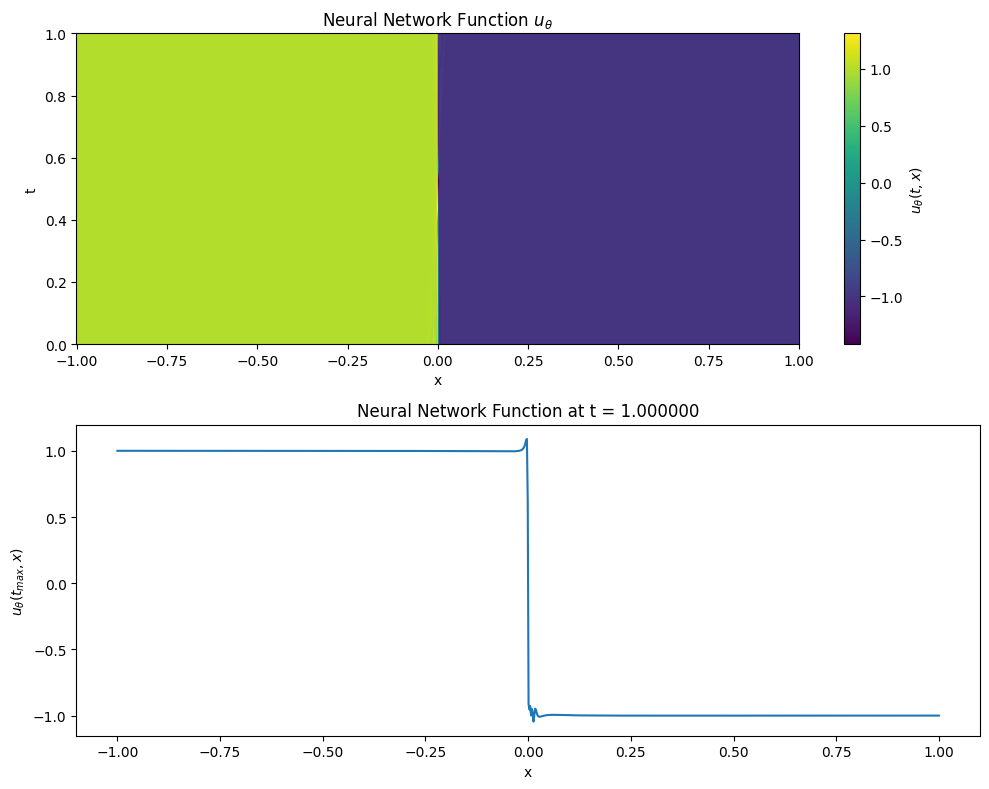


Starting Train Stage with MGDL

Stage 1: Sequential Grade Training

Training Grade 0
Train time for stage1: 0.553226 seconds


ZeroDivisionError: float division by zero

In [3]:
optProb.train_process_stage1(grade_epochs=[0])

In [5]:
optProb.pwp.triangles.shape

(4096, 3, 2)

In [4]:
vertices_all = optProb.pwp.triangles
params = optProb.model.mlps[0].params
Nt = optProb.pwp.N_elements
u_values_all = optProb.u_eval(params, vertices_all.reshape(-1, 2)).reshape(Nt, 3)
A_all = jnp.stack([jnp.ones((Nt, 3)), vertices_all[:, :, 0], vertices_all[:, :, 1]], axis=-1)
init_coeffs_all = jnp.linalg.solve(A_all, u_values_all[..., None]).squeeze(-1)

In [15]:
maximize_kh_step

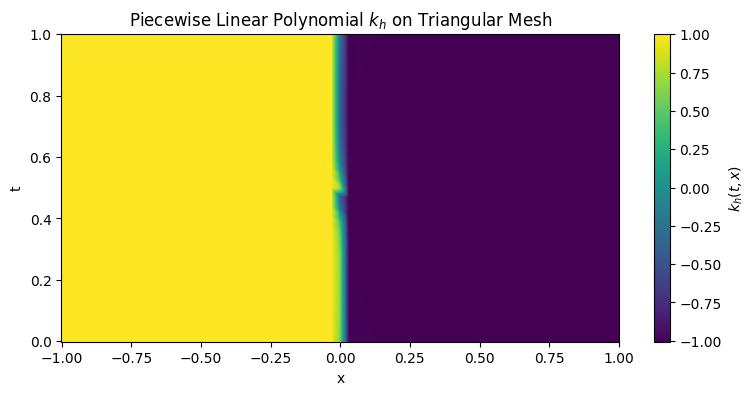

In [16]:
plot_kh(optProb.pwp)

In [41]:
optProb.N_perturb = 100000
optProb.sigma=1
optProb.pwp.coeffs, optProb.key, loss_eqn_from_kh, loss_eqn_abs = optProb.maximize_kh_step(params, optProb.key)

In [44]:
pwp_coef = jax.numpy.copy(optProb.pwp.coeffs)

(320, 640)


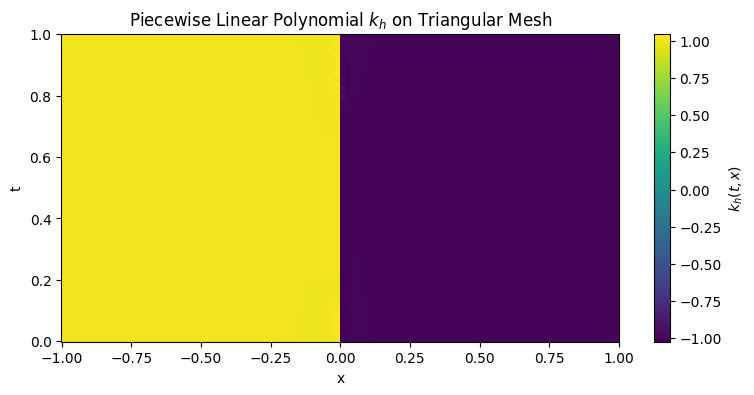

In [45]:
mid_pnts = jnp.average(vertices_all, axis=1)
mid_vals = optProb.u_eval(params, mid_pnts)
init_coeffs_all = jnp.hstack([mid_vals[..., None] , jnp.zeros((Nt, 2))])
optProb.pwp.coeffs = init_coeffs_all
plot_kh(optProb.pwp)

In [46]:
optProb.pwp.coeffs = pwp_coef
plot_kh(optProb.pwp)

(320, 640)


XlaRuntimeError: INTERNAL: Buffer Definition Event: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error preparing computation: Out of memory allocating 314572800000 bytes.

In [38]:
def plot_kh(pwp, M_factor=10):
    """
    Plot the piecewise linear polynomial k_h over the domain [t_min, t_max] x [x_min, x_max]
    on a triangular mesh, using JAX for efficiency.

    Args:
        pwp: PiecewiseLinearPolynomials instance with N_t, N_x, t_min, t_max, x_min, x_max, and coeffs.
        M_factor: Factor to refine the plotting grid (default: 10).
    """
    # Retrieve ranges and grid parameters from pwp
    t_min, t_max = pwp.t_min, pwp.t_max
    x_min, x_max = pwp.x_min, pwp.x_max
    N_t, N_x = pwp.N_t, pwp.N_x
    tau = (t_max - t_min) / N_t  # Step size for t
    hx = (x_max - x_min) / N_x   # Step size for x

    # Create fine grid using JAX arrays
    M_t, M_x = N_t * M_factor, N_x * M_factor
    t_grid = jnp.linspace(t_min, t_max, M_t)
    x_grid = jnp.linspace(x_min, x_max, M_x)
    t, x = jnp.meshgrid(t_grid, x_grid, indexing='ij')  # Shapes: (M_t, M_x)

    # Flatten the grid for vectorized operations
    tx_points = jnp.stack([t.ravel(), x.ravel()], axis=1)  # Shape: (M_t * M_x, 2)

    # Function to find the element index for a single point
    def find_element(tx):
        t_val, x_val = tx
        # Find the rectangle containing the point
        i = jnp.floor((t_val - t_min) / tau).astype(int)
        j = jnp.floor((x_val - x_min) / hx).astype(int)
        i = jnp.clip(i, 0, N_t - 1)
        j = jnp.clip(j, 0, N_x - 1)

        # Get vertices of the two triangles in this rectangle
        A = jnp.array([t_min + i * tau, x_min + j * hx])
        B = jnp.array([t_min + (i + 1) * tau, x_min + j * hx])
        C = jnp.array([t_min + i * tau, x_min + (j + 1) * hx])
        D = jnp.array([t_min + (i + 1) * tau, x_min + (j + 1) * hx])

        # Check which triangle contains the point
        in_triangle_1 = point_in_triangle(tx, A, B, C)
        in_triangle_2 = point_in_triangle(tx, B, D, C)
        global_idx = jnp.where(
            in_triangle_1,
            2 * (i * N_x + j),        # First triangle
            jnp.where(
                in_triangle_2,
                2 * (i * N_x + j) + 1,  # Second triangle
                -1                      # Not in any triangle
            )
        )
        return global_idx

    # Vectorize the find_element function over all points
    element_indices = vmap(find_element)(tx_points)  # Shape: (M_t * M_x,)

    # Evaluate k_h at all points using their corresponding element indices
    kh_values = pwp.evaluate(tx_points, element_indices)  # Shape: (M_t * M_x,)
    kh_values = kh_values.reshape(M_t, M_x)  # Reshape to (M_t, M_x)
    print(kh_values.shape)
    kh_values = np.asarray(kh_values)

    # Plot using pcolormesh
    height = int((t_max - t_min)*4)
    width = int((x_max - x_min)*4 + 1)
    plt.figure(figsize=(width, height))
    plt.pcolormesh(x_grid, t_grid, kh_values, shading='nearest', cmap='viridis')
    plt.colorbar(label='$k_h(t, x)$')
    plt.xlabel('x')
    plt.ylabel('t')
    plt.title('Piecewise Linear Polynomial $k_h$ on Triangular Mesh')
    plt.show()

In [39]:
u_val_at_vetices = optProb.u_eval(params, vertices_all)
avg_vals = jnp.average(u_val_at_vetices, axis=1)
init_coeffs_all = jnp.hstack([avg_vals[..., None] , jnp.zeros((Nt, 2))])
# optProb.pwp.coeffs = init_coeffs_all
plot_kh(optProb.pwp)
plt.plot(avg_vals)

(320, 640)


XlaRuntimeError: INTERNAL: Buffer Definition Event: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error preparing computation: Out of memory allocating 314572800000 bytes.

In [40]:
p_temp = optProb.pwp.coeffs

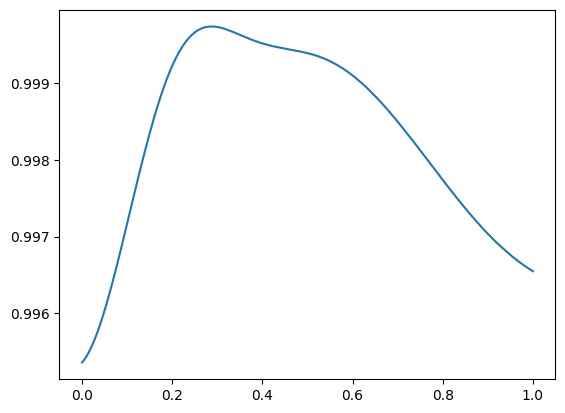

In [81]:
tt = jnp.linspace(0, 1, 1000)
c= -0.05
tx = jnp.hstack([tt[..., None], c*jnp.ones((1000,1))])
plt.plot(tt, optProb.u_eval(params, tx))

In [49]:
pwp_coef

XlaRuntimeError: INTERNAL: Buffer Definition Event: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error dispatching computation: Error preparing computation: Out of memory allocating 314572800000 bytes.